# 03 · Abschliessende Auswertung auf zurückgehaltenen Beispielen

Prüft die in 02 eingefrorene Methode fair für beide Modelle: Dissoziation, Reaktionsregeln, Modellvergleich und Transfer.
Zwei Teile, beide mit derselben eingefrorenen Methode:
1. **Test (MNLI):** 327 zurückgehaltene Paare aus derselben Quelle wie das Training.
2. **Unbekannte Eingaben (SNLI):** 300 Paare aus einer anderen Quelle. Nichts wird darauf angepasst.

Nach einem Ergebnis die Schwellen anpassen und denselben Test erneut als unabhängige Prüfung verwenden wäre methodisch falsch.

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "config/project.json").exists())
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
from IPython.display import display, Image
from uncertainty_project.common import config
CFG = config(ROOT)
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
print("Projekt:", ROOT.name, "| Modelle:", list(CFG["models"]))

Projekt: uncertainty_project | Modelle: ['gpt', 'claude']


In [2]:
from uncertainty_project.data import load_split
from uncertainty_project.api import request_plan, collect_predictions, model_keys
from uncertainty_project.experiment import verify_frozen, final_evaluation, experiment_directory

RUN_FINAL_TEST = True
MAX_NEW_REQUESTS = 2000   # pro Modell und Teil: Test ca. 327 x 5 = 1635 Calls, unbekannte Eingaben 300 x 5 = 1500
TEST_READY = False
try:
    protocol = verify_frozen(ROOT)
    TEST_READY = True
    test_inputs = load_split(ROOT, "test")
    shift_inputs = load_split(ROOT, "shift")
    plan = [{"teil": "test", **request_plan(ROOT, test_inputs, k)} for k in model_keys(ROOT)]
    plan += [{"teil": "unbekannt (SNLI)", **request_plan(ROOT, shift_inputs, k)} for k in model_keys(ROOT)]
    display(pd.DataFrame(plan).drop(columns="note"))
except (RuntimeError, FileNotFoundError) as exc:
    print(str(exc))

,teil,model_key,model,examples,variants,logical_requests,cached,new_requests,max_output_tokens_per_request
0,test,gpt,gpt-6.1-sol,327,5,1635,0,1635,4096
1,test,claude,claude-sonnet-5-5,327,5,1635,0,1635,4096
2,unbekannt (SNLI),gpt,gpt-6.1-sol,300,5,1500,0,1500,4096
3,unbekannt (SNLI),claude,claude-sonnet-5-5,300,5,1500,0,1500,4096


In [3]:
report = None
if TEST_READY and RUN_FINAL_TEST:
    for k in model_keys(ROOT):
        print(f"--- {k}: Test")
        collect_predictions(ROOT, test_inputs, k, allow_api=True, max_new_requests=MAX_NEW_REQUESTS)
        print(f"--- {k}: unbekannte Eingaben")
        collect_predictions(ROOT, shift_inputs, k, allow_api=True, max_new_requests=MAX_NEW_REQUESTS)
    report = final_evaluation(ROOT)
    OUT = experiment_directory(ROOT) / "test"
    for k, res in report["per_model"].items():
        print(f"\n=== TEST · {k}")
        display(res["dissociation"].round(3))
        print("Vorab festgelegte Vergleiche (gepaarte AUROC-Differenzen, primary = Hauptaussagen):")
        display(res["specialisation"].round(3))
        display(res["policies"].round(3))
        display(res["policy_intervals"])
        display(res["confusion_decomposed"])
    display(report["model_comparison"].round(3)); print(report["model_comparison"].attrs)
    display(report["transfer_summary"].round(3))
    display(pd.DataFrame(report["paired_intervals"]).T.round(4))
else:
    print("Kein finaler Test ausgeführt. RUN_FINAL_TEST erst nach Abschluss von Notebook 02 aktivieren.")

--- gpt: Test
[gpt] 1/1635 processed, 0 failed
[gpt] 50/1635 processed, 0 failed
[gpt] 100/1635 processed, 0 failed
[gpt] 150/1635 processed, 0 failed
[gpt] 200/1635 processed, 0 failed
[gpt] 250/1635 processed, 0 failed
[gpt] 300/1635 processed, 0 failed
[gpt] 350/1635 processed, 0 failed
[gpt] 400/1635 processed, 0 failed
[gpt] 450/1635 processed, 0 failed
[gpt] 500/1635 processed, 0 failed
[gpt] 550/1635 processed, 0 failed
[gpt] 600/1635 processed, 0 failed
[gpt] 650/1635 processed, 0 failed
[gpt] 700/1635 processed, 0 failed
[gpt] 750/1635 processed, 0 failed
[gpt] 800/1635 processed, 0 failed
[gpt] 850/1635 processed, 0 failed
[gpt] 900/1635 processed, 0 failed
[gpt] 950/1635 processed, 0 failed
[gpt] 1000/1635 processed, 0 failed
[gpt] 1050/1635 processed, 0 failed
[gpt] 1100/1635 processed, 0 failed
[gpt] 1150/1635 processed, 0 failed
[gpt] 1200/1635 processed, 0 failed
[gpt] 1250/1635 processed, 0 failed
[gpt] 1300/1635 processed, 0 failed
[gpt] 1350/1635 processed, 0 failed
[

,signal,intended_component,auroc_debatable,auroc_error_on_clear_cases,spearman_human_entropy,auroc_error_all_cases,n,n_clear,errors_on_clear,auroc_debatable_ci_low,auroc_debatable_ci_high,auroc_error_on_clear_ci_low,auroc_error_on_clear_ci_high
0,model_total_entropy,mixed,0.543,0.809,0.121,0.696,327,94,32,0.482,0.600,0.696,0.908
1,model_expected_entropy,aleatoric,0.544,0.803,0.116,0.698,327,94,32,0.486,0.602,0.691,0.902
2,model_epistemic_mi,epistemic,0.534,0.782,0.107,0.633,327,94,32,0.476,0.598,0.680,0.882
3,model_credal_width,epistemic,0.538,0.827,0.116,0.671,327,94,32,0.481,0.595,0.727,0.923
4,model_label_flips,epistemic,0.496,0.574,0.022,0.519,327,94,32,0.461,0.530,0.498,0.661
5,model_one_minus_confidence,mixed,0.529,0.801,0.089,0.689,327,94,32,0.468,0.588,0.687,0.900
6,learned_human_entropy,aleatoric,0.711,0.617,0.405,0.592,327,94,32,0.654,0.763,0.490,0.726
7,learned_epistemic_risk,epistemic,0.567,0.889,0.107,0.778,327,94,32,0.506,0.629,0.794,0.953
8,learned_risk_all_cases,mixed,0.574,0.907,0.147,0.784,327,94,32,0.514,0.634,0.831,0.960
9,baseline_answer_label,baseline,0.541,0.737,0.078,0.649,327,94,32,0.491,0.592,0.655,0.809


Vorab festgelegte Vergleiche (gepaarte AUROC-Differenzen, primary = Hauptaussagen):


,rank,target,signal,minus,auroc_difference,ci_95_low,ci_95_high,valid_resamples,question
0,primary,debatable,learned_human_entropy,learned_epistemic_risk,0.144,0.068,0.232,500,Does the disagreement signal detect debatable ...
1,primary,error_on_clear,learned_epistemic_risk,learned_human_entropy,0.272,0.144,0.413,500,Does the risk signal detect majority deviation...
2,primary,error_on_clear,learned_epistemic_risk,baseline_label_confidence,-0.015,-0.038,0.002,500,"Do ensemble signals (MI, credal width, cues) a..."
3,secondary,debatable,learned_entropy_direct,learned_human_entropy,0.007,-0.039,0.050,500,Robustness: does predicting human entropy dire...


,method,balanced_accuracy,accuracy,recall_answer,recall_hedge,recall_debatable,answer_fraction,hedge_fraction,alternatives_fraction,clarify_fraction,unwarranted_answer_rate,n_reference_clarify,recall_clarify_annotated,n_reference_alternatives,recall_alternatives_annotated,fine_balanced_accuracy_annotated,conditional_n,conditional_clarify_vs_alternatives_accuracy
0,decomposed,0.610,0.523,0.814,0.70,0.317,0.450,0.333,0.174,0.043,0.463,16,0.125,27,0.370,0.248,19,0.632
1,risk_trained_all_cases,0.634,0.636,0.649,0.62,0.633,0.294,0.232,0.404,0.070,0.344,16,0.125,27,0.556,0.340,27,0.630
2,single_score_risk,0.534,0.352,0.742,0.86,0.000,0.462,0.538,0.000,0.000,0.523,16,0.000,27,0.000,0.000,0,NaN
3,single_score_confidence,0.488,0.333,0.763,0.70,0.000,0.599,0.401,0.000,0.000,0.622,16,0.000,27,0.000,0.000,0,NaN
4,raw,0.465,0.330,0.814,0.58,0.000,0.703,0.297,0.000,0.000,0.657,16,0.000,27,0.000,0.000,0,NaN
5,calibrated,0.430,0.606,0.412,0.00,0.878,0.202,0.000,0.642,0.156,0.394,16,0.312,27,0.778,0.545,41,0.634
6,always_answer,0.333,0.297,1.000,0.00,0.000,1.000,0.000,0.000,0.000,0.703,16,0.000,27,0.000,0.000,0,NaN
7,always_hedge,0.333,0.153,0.000,1.00,0.000,0.000,1.000,0.000,0.000,NaN,16,0.000,27,0.000,0.000,0,NaN
8,always_alternatives,0.333,0.550,0.000,0.00,1.000,0.000,0.000,1.000,0.000,NaN,16,0.000,27,1.000,0.500,43,0.628


,comparison,estimate,ci_95_low,ci_95_high,valid_resamples,direction
0,balanced_accuracy_decomposed_minus_risk_traine...,-0.023906,-0.070144,0.019174,500,positive favours decomposed over risk_trained_...
1,balanced_accuracy_decomposed_minus_single_scor...,0.076277,0.022447,0.12442,500,positive favours decomposed over single_score_...
2,balanced_accuracy_decomposed_minus_single_scor...,0.122738,0.065041,0.179228,500,positive favours decomposed over single_score_...
3,balanced_accuracy_decomposed_minus_calibrated,0.180317,0.122282,0.231968,500,positive favours decomposed over calibrated


... (8 outputs left out)

,model,js_divergence,expected_brier,majority_agreement,human_support_of_answer,human_support_ece,entropy_spearman,mean_epistemic_mi,label_flip_rate,mean_credal_width
0,gpt,0.144,0.731,0.593,0.524,0.322,0.121,0.011,0.104,0.071
1,claude,0.073,0.588,0.657,0.553,0.115,0.130,0.013,0.183,0.104


{'paired_majority_agreement_difference': {'mean_difference': -0.06422018348623854, 'ci_95_low': -0.12039009287925696, 'ci_95_high': -0.015235824059353482, 'groups': 272, 'bootstrap_repetitions': 500, 'direction': 'positive: gpt agrees with the majority more often than claude'}, 'same_answer_rate': 0.746177370030581}


,assessor_from,applied_to,policy_bal_acc_transfer,policy_bal_acc_own,human_js_transfer,human_js_own,clear_error_auroc_transfer,clear_error_auroc_own
0,gpt,claude,0.433,0.498,0.064,0.045,0.704,0.804
1,claude,gpt,0.475,0.610,0.062,0.050,0.813,0.889


,mean_difference,ci_95_low,ci_95_high,groups,bootstrap_repetitions,direction,estimate,valid_resamples
gpt_human_js_tree_minus_prompt_mean,-0.094088,-0.105861,-0.083633,272,500,negative favours the tree,NaN,NaN
gpt_balanced_accuracy_decomposed_minus_risk_trained_all_cases,NaN,-0.070144,0.019174,NaN,NaN,positive favours decomposed over risk_trained_...,-0.023906,500
gpt_balanced_accuracy_decomposed_minus_single_score_risk,NaN,0.022447,0.12442,NaN,NaN,positive favours decomposed over single_score_...,0.076277,500
gpt_balanced_accuracy_decomposed_minus_single_score_confidence,NaN,0.065041,0.179228,NaN,NaN,positive favours decomposed over single_score_...,0.122738,500
gpt_balanced_accuracy_decomposed_minus_calibrated,NaN,0.122282,0.231968,NaN,NaN,positive favours decomposed over calibrated,0.180317,500
claude_human_js_tree_minus_prompt_mean,-0.027714,-0.035733,-0.020573,272,500,negative favours the tree,NaN,NaN
claude_balanced_accuracy_decomposed_minus_risk_trained_all_cases,NaN,-0.096234,-0.0024,NaN,NaN,positive favours decomposed over risk_trained_...,-0.046157,500
claude_balanced_accuracy_decomposed_minus_single_score_risk,NaN,-0.110534,0.025274,NaN,NaN,positive favours decomposed over single_score_...,-0.042697,500
claude_balanced_accuracy_decomposed_minus_single_score_confidence,NaN,-0.026777,0.12811,NaN,NaN,positive favours decomposed over single_score_...,0.054301,500
claude_balanced_accuracy_decomposed_minus_calibrated,NaN,-0.036329,0.124172,NaN,NaN,positive favours decomposed over calibrated,0.048402,500


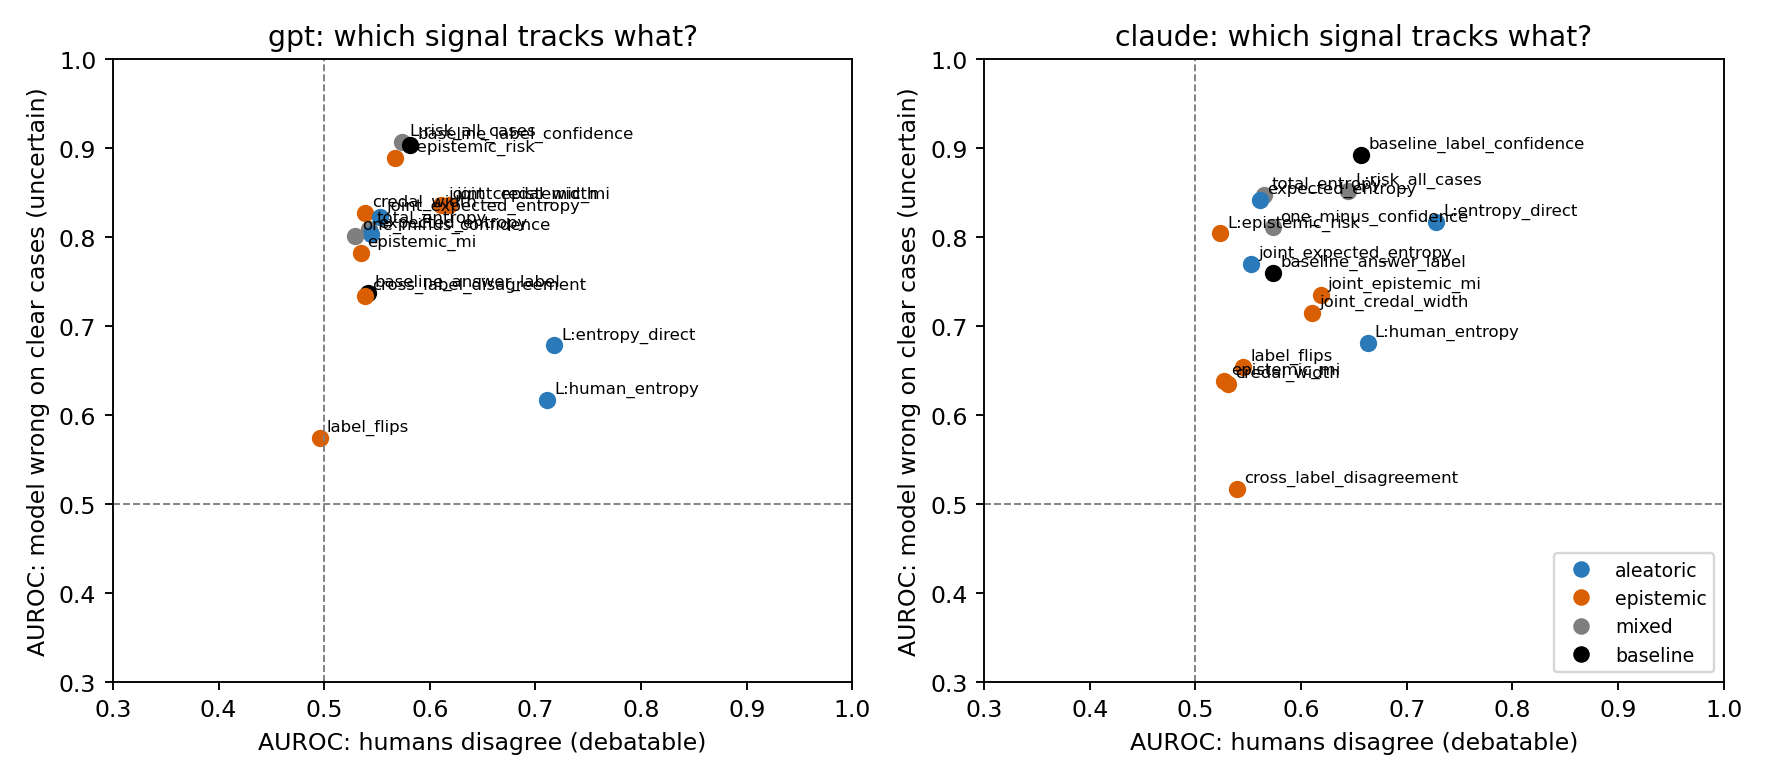

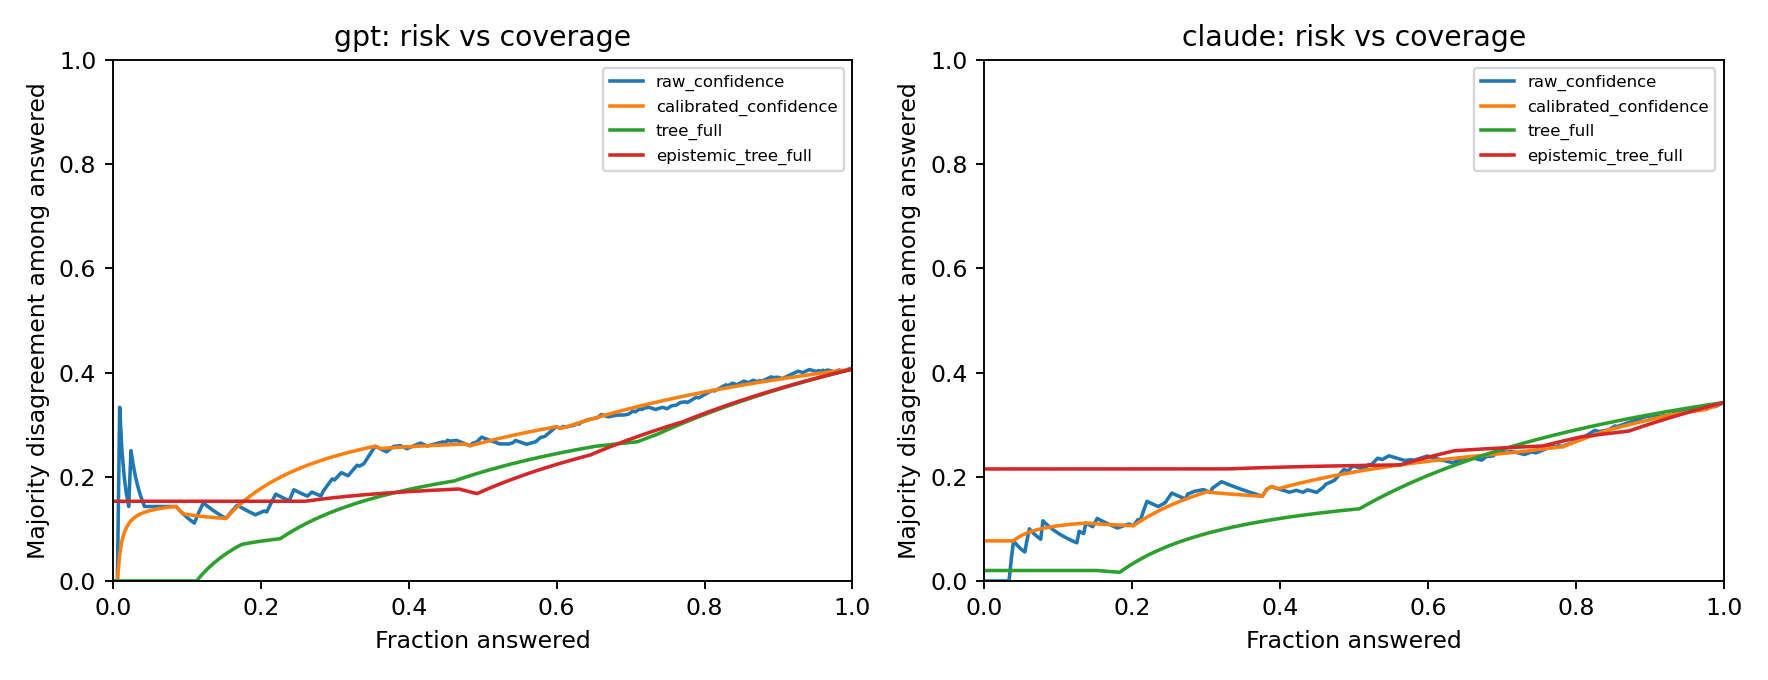

Alle Tabellen: outputs\experiments\chaos_mnli_v2_two_models_0ed06cd43089\test


In [4]:
if report is not None:
    display(Image(filename=str(OUT / "dissociation.png")))
    display(Image(filename=str(OUT / "risk_coverage.png")))
    print("Alle Tabellen:", OUT.relative_to(ROOT))


=== UNBEKANNTE EINGABEN · gpt


,signal,intended_component,auroc_debatable,auroc_error_on_clear_cases,spearman_human_entropy,auroc_error_all_cases,n,n_clear,errors_on_clear,auroc_debatable_ci_low,auroc_debatable_ci_high,auroc_error_on_clear_ci_low,auroc_error_on_clear_ci_high
0,model_total_entropy,mixed,0.771,0.816,0.617,0.786,300,216,19,0.713,0.826,0.711,0.916
1,model_expected_entropy,aleatoric,0.777,0.801,0.629,0.771,300,216,19,0.721,0.832,0.696,0.892
2,model_epistemic_mi,epistemic,0.710,0.822,0.488,0.801,300,216,19,0.642,0.777,0.710,0.934
3,model_credal_width,epistemic,0.740,0.811,0.550,0.792,300,216,19,0.678,0.798,0.697,0.932
4,model_label_flips,epistemic,0.507,0.677,0.167,0.667,300,216,19,0.470,0.551,0.572,0.789
5,model_one_minus_confidence,mixed,0.759,0.806,0.606,0.779,300,216,19,0.699,0.816,0.701,0.911
6,learned_human_entropy,aleatoric,0.569,0.621,0.162,0.625,300,216,19,0.492,0.658,0.465,0.763
7,learned_epistemic_risk,epistemic,0.659,0.593,0.319,0.549,300,216,19,0.568,0.742,0.419,0.750
8,learned_risk_all_cases,mixed,0.666,0.635,0.392,0.600,300,216,19,0.584,0.748,0.504,0.750
9,baseline_answer_label,baseline,0.578,0.559,0.230,0.532,300,216,19,0.508,0.642,0.449,0.666


Vorab festgelegte Vergleiche (gepaarte AUROC-Differenzen, primary = Hauptaussagen):


,rank,target,signal,minus,auroc_difference,ci_95_low,ci_95_high,valid_resamples,question
0,primary,debatable,learned_human_entropy,learned_epistemic_risk,-0.091,-0.192,0.014,500,Does the disagreement signal detect debatable ...
1,primary,error_on_clear,learned_epistemic_risk,learned_human_entropy,-0.028,-0.206,0.146,500,Does the risk signal detect majority deviation...
2,primary,error_on_clear,learned_epistemic_risk,baseline_label_confidence,-0.012,-0.053,0.033,500,"Do ensemble signals (MI, credal width, cues) a..."
3,secondary,debatable,learned_entropy_direct,learned_human_entropy,0.083,0.039,0.137,500,Robustness: does predicting human entropy dire...


,method,js_divergence,expected_brier,majority_agreement,human_support_of_answer,human_support_ece,entropy_spearman
0,training_prior,0.204,0.639,0.277,0.307,0.110,NaN
1,single_prompt,0.068,0.438,0.857,0.725,0.161,0.619
2,prompt_mean,0.063,0.428,0.853,0.722,0.154,0.617
3,calibrated_prompt_mean,0.075,0.412,0.853,0.722,0.113,0.588
4,tree_score_only,0.090,0.461,0.723,0.666,0.077,0.087
5,tree_no_concepts,0.086,0.455,0.710,0.648,0.042,0.151
6,tree_full,0.086,0.455,0.710,0.648,0.046,0.162


,method,subset,n,errors,error_brier,correctness_ece,error_auroc,aurc
0,raw_confidence,all,300,44,0.107,0.042,0.779,0.054
1,raw_confidence,clear_cases,216,19,0.066,0.034,0.806,0.028
2,calibrated_confidence,all,300,44,0.153,0.187,0.755,0.059
3,calibrated_confidence,clear_cases,216,19,0.122,0.201,0.775,0.033
4,answer_label_only,all,300,44,0.203,0.254,0.518,0.142
5,answer_label_only,clear_cases,216,19,0.182,0.275,0.537,0.082
6,epistemic_answer_label_only,all,300,44,0.246,0.314,0.532,0.129
7,epistemic_answer_label_only,clear_cases,216,19,0.223,0.317,0.559,0.069
8,tree_score_only,all,300,44,0.205,0.207,0.642,0.086
9,tree_score_only,clear_cases,216,19,0.157,0.198,0.683,0.044


... (7 outputs left out)

,method,subset,n,errors,error_brier,correctness_ece,error_auroc,aurc
0,raw_confidence,all,300,41,0.113,0.148,0.850,0.034
1,raw_confidence,clear_cases,216,12,0.077,0.170,0.883,0.009
2,calibrated_confidence,all,300,41,0.115,0.133,0.842,0.035
3,calibrated_confidence,clear_cases,216,12,0.079,0.157,0.877,0.010
4,answer_label_only,all,300,41,0.203,0.265,0.494,0.132
5,answer_label_only,clear_cases,216,12,0.181,0.310,0.552,0.046
6,epistemic_answer_label_only,all,300,41,0.219,0.277,0.494,0.132
7,epistemic_answer_label_only,clear_cases,216,12,0.186,0.298,0.552,0.046
8,tree_score_only,all,300,41,0.132,0.153,0.773,0.053
9,tree_score_only,clear_cases,216,12,0.098,0.179,0.791,0.018


,method,balanced_accuracy,accuracy,recall_answer,recall_hedge,recall_debatable,answer_fraction,hedge_fraction,alternatives_fraction,clarify_fraction,unwarranted_answer_rate,n_reference_clarify,recall_clarify_annotated,n_reference_alternatives,recall_alternatives_annotated,fine_balanced_accuracy_annotated,conditional_n,conditional_clarify_vs_alternatives_accuracy
0,decomposed,0.440,0.477,0.538,0.60,0.182,0.457,0.473,0.067,0.003,0.117,0,None,0,None,None,0,None
1,risk_trained_all_cases,0.468,0.643,0.773,0.45,0.182,0.683,0.247,0.067,0.003,0.151,0,None,0,None,None,0,None
2,single_score_risk,0.446,0.627,0.787,0.55,0.000,0.693,0.307,0.000,0.000,0.149,0,None,0,None,None,0,None
3,single_score_confidence,0.511,0.740,0.933,0.60,0.000,0.830,0.170,0.000,0.000,0.157,0,None,0,None,None,0,None
4,raw,0.526,0.740,0.929,0.65,0.000,0.810,0.190,0.000,0.000,0.140,0,None,0,None,None,0,None
5,calibrated,0.511,0.740,0.933,0.60,0.000,0.830,0.170,0.000,0.000,0.157,0,None,0,None,None,0,None
6,always_answer,0.333,0.750,1.000,0.00,0.000,1.000,0.000,0.000,0.000,0.250,0,None,0,None,None,0,None
7,always_hedge,0.333,0.067,0.000,1.00,0.000,0.000,1.000,0.000,0.000,NaN,0,None,0,None,None,0,None
8,always_alternatives,0.333,0.183,0.000,0.00,1.000,0.000,0.000,1.000,0.000,NaN,0,None,0,None,None,0,None


,comparison,estimate,ci_95_low,ci_95_high,valid_resamples,direction
0,balanced_accuracy_decomposed_minus_risk_traine...,-0.028519,-0.112733,0.056394,500,positive favours decomposed over risk_trained_...
1,balanced_accuracy_decomposed_minus_single_scor...,-0.00569,-0.106541,0.087793,500,positive favours decomposed over single_score_...
2,balanced_accuracy_decomposed_minus_single_scor...,-0.071246,-0.1459,0.005763,500,positive favours decomposed over single_score_...
3,balanced_accuracy_decomposed_minus_calibrated,-0.071246,-0.1459,0.005763,500,positive favours decomposed over calibrated


,assessor_from,applied_to,policy_bal_acc_transfer,policy_bal_acc_own,human_js_transfer,human_js_own,clear_error_auroc_transfer,clear_error_auroc_own
0,gpt,claude,0.346,0.440,0.132,0.073,0.558,0.756
1,claude,gpt,0.389,0.397,0.076,0.086,0.631,0.593


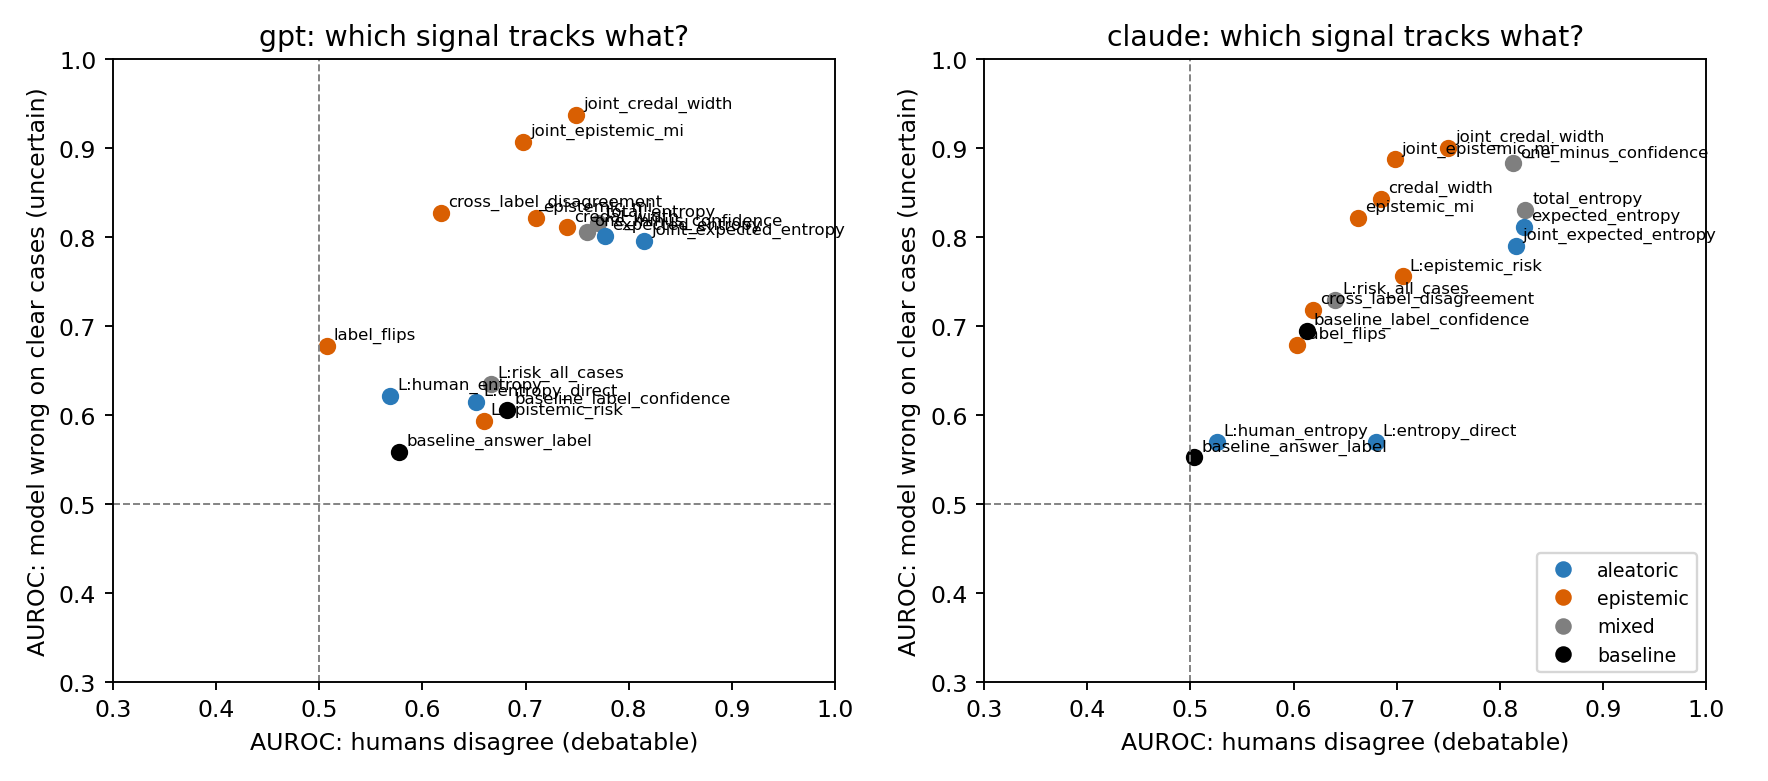

In [5]:
if report is not None and "shift" in report:
    SHIFT_OUT = experiment_directory(ROOT) / "shift"
    for k, res in report["shift"]["per_model"].items():
        print(f"\n=== UNBEKANNTE EINGABEN · {k}")
        display(res["dissociation"].round(3))
        print("Vorab festgelegte Vergleiche (gepaarte AUROC-Differenzen, primary = Hauptaussagen):")
        display(res["specialisation"].round(3))
        display(res["distributions"].round(3))
        display(res["error_risk"].round(3))
        display(res["policies"].round(3))
        display(res["policy_intervals"])
    display(report["shift"]["transfer_summary"].round(3))
    display(Image(filename=str(SHIFT_OUT / "dissociation.png")))

## So liest du die Ergebnisse

- **Dissoziation:** die zentrale Antwort auf den Projekttitel. Helfen die Signale, menschliche Uneinigkeit und
  Mehrheitsabweichungen auf klaren Fällen auseinanderzuhalten? Intervalle beachten.
- **Policies:** Trifft `decomposed` die Referenzreaktionen besser als ein einzelner Score, ein auf allen Fällen trainiertes
  Risiko und reine Konfidenz? Die Intervalle `balanced_accuracy_decomposed_minus_*` zeigen, ob der Unterschied belastbar ist.
- **Modellvergleich:** Wie unterscheiden sich GPT und Claude auf identischen Beispielen?
- **Transfer:** Wie viel geht verloren, wenn der Bewerter vom anderen Modell stammt?
- **Unbekannte Eingaben:** Gleiche Tabellen auf SNLI. Bleiben die Werte ähnlich wie im Test, hat der Bewerter etwas
  Allgemeines gelernt. Brechen sie ein, ist er an MNLI gebunden. SNLI ist nur eine milde Verschiebung (gleiche Aufgabe).
- **Grenzen:** wenige Modellfehler auf klaren Fällen machen AUROC-Werte unsicher. Mehrheitsabweichung ist nicht objektiv falsch.
  Öffentliche NLI-Daten könnten im Vortraining vorgekommen sein. Referenzreaktionen sind eine Definition, keine Nutzerbefragung.